# SI Fig. S1: experimental controls for Expt 1

S1c, S1d  barcode frequencies from two libraries prepared independently from the
            same flask, and the histogram of their ratio.  Agreement here shows the
            per-barcode counts are not dominated by PCR or sequencing noise.

  S1e, S1f  count histograms at the first and last timepoints, with the cutoffs that
            define a genuine lineage marked.  Both cutoffs sit in a visible gap: the
            lower one below the singleton-peaked error mode, the upper one below a
            small outlier mode of lineages that already carried a resistant mutation.

  S1g       barcode frequency at each timepoint against the next.  Stability by the
            last two timepoints is the evidence that lineages have no appreciable
            fitness differences under selection, so barcode frequencies are not
            distorted by competition.

Timepoints: D501 is t0, D502 its technical replicate, D503-D506 are t1-t4.
The replicate R^2 is reported to stdout rather than plotted.  Runtime: ~1 min.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import sys, time

import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import load_npz

from barfly.plotting import use_paper_style      # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
DATA = ROOT / "data" / "expt1"
use_paper_style()

MINREADS = 10
UPPERCUTOFF = 1e5
t_start = time.time()

In [2]:
def col0(path, rows):
    m = load_npz(path)
    return m, np.array([m[i, 0] for i in rows])

In [3]:
sys.path.insert(0, str(ROOT))
from barfly.plotting import use_paper_style      # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
DATA = ROOT / "data" / "expt1"
use_paper_style()

MINREADS = 10
UPPERCUTOFF = 1e5
t_start = time.time()

def col0(path, rows):
    m = load_npz(path)
    return m, np.array([m[i, 0] for i in rows])

## S1e: counts at t0, with the lower cutoff

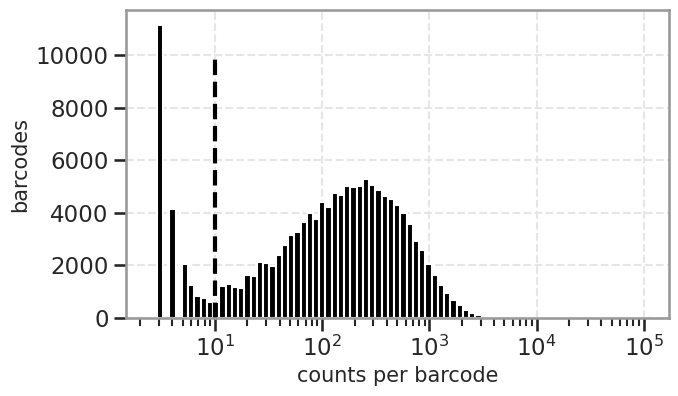

In [4]:
counts_t0 = load_npz(DATA / "D709_D501_errorCorrectedBcds.npz")
present_at_t0 = counts_t0.nonzero()[0]
counts_0_all = np.array([counts_t0[i, 0] for i in present_at_t0])

fig = plt.figure(figsize=(7, 4))
plt.hist(counts_0_all, bins=np.logspace(0.4, 5, 80), color="k")
plt.xscale("log")
plt.plot([MINREADS, MINREADS], [0, 10000], '--k', linewidth=3)
plt.xlabel("counts per barcode"); plt.ylabel("barcodes")
plt.savefig(OUT / "figS01e_umisPerBarcode_t0.svg", dpi=300); plt.show()

## S1c, S1d: technical replicates

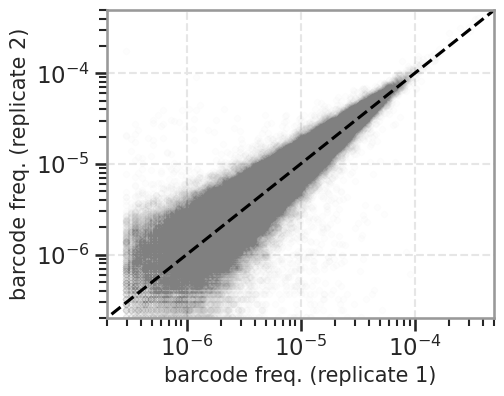

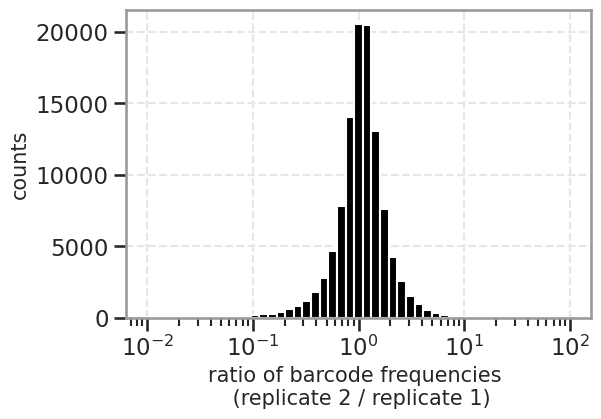

11895 / 119724 barcodes have zero reads in replicate 2, excluded from R^2
replicate R^2 (linear space): 0.9046
replicate R^2 (log space):    0.7377
7230 / 107829 barcodes more than 3x off the x = y line


In [5]:
counts_replicate = load_npz(DATA / "D709_D502_errorCorrectedBcds.npz")
bcds = np.array([i for i in present_at_t0 if counts_t0[i, 0] > MINREADS])
counts_rep1 = np.array([counts_t0[i, 0] for i in bcds])
counts_rep2 = np.array([counts_replicate[i, 0] for i in bcds])
freq1 = counts_rep1 / np.sum(counts_rep1)
freq2 = counts_rep2 / np.sum(counts_rep2)

fig = plt.figure(); fig.set_size_inches(5, 4)
plt.plot(freq1, freq2, ".", color="gray", alpha=0.01, rasterized=True)
plt.xscale("log"); plt.yscale("log")
plt.plot([1e-7, 1e-3], [1e-7, 1e-3], '--k')
plt.xlim([2e-7, 5e-4]); plt.ylim([2e-7, 5e-4])
plt.xlabel("barcode freq. (replicate 1)"); plt.ylabel("barcode freq. (replicate 2)")
plt.savefig(OUT / "figS01c_replicatePCRs.svg", dpi=300); plt.show()

fig = plt.figure(); fig.set_size_inches(6, 4)
plt.hist(freq2 / freq1, bins=np.logspace(-2, 2, 50), color="k")
plt.xscale("log")
plt.xlabel("ratio of barcode frequencies \n (replicate 2 / replicate 1)")
plt.ylabel("counts")
plt.savefig(OUT / "figS01d_replicatePCRs_ratio.svg", dpi=300); plt.show()

valid = counts_rep2 > 0
print(f"{np.sum(~valid)} / {len(valid)} barcodes have zero reads in replicate 2, "
      f"excluded from R^2")
print(f"replicate R^2 (linear space): {np.corrcoef(freq1[valid], freq2[valid])[0,1]**2:.4f}")
print(f"replicate R^2 (log space):    "
      f"{np.corrcoef(np.log10(freq1[valid]), np.log10(freq2[valid]))[0,1]**2:.4f}")
ratio = freq2[valid] / freq1[valid]
print(f"{np.sum((ratio > 3) | (ratio < 1/3))} / {np.sum(valid)} barcodes more than "
      f"3x off the x = y line")

## S1g: successive timepoints

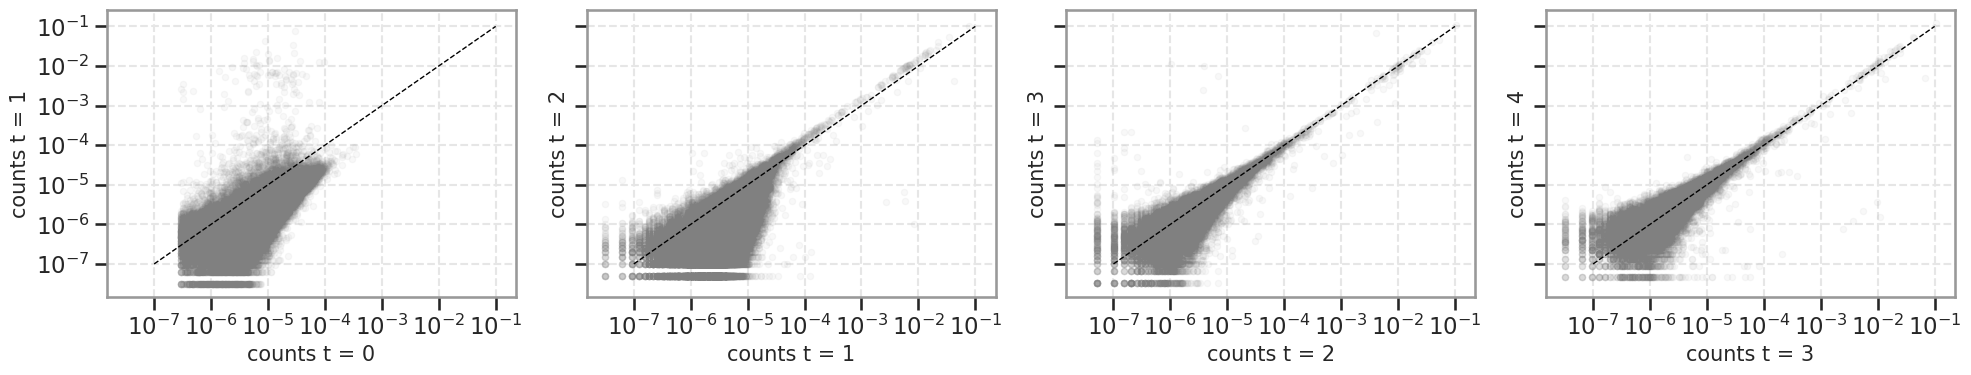

In [6]:
TIMEPOINTS = ["1", "3", "4", "5", "6"]        # D50x for t = 0 .. 4
count_matrix = np.zeros([len(TIMEPOINTS), len(bcds)])
for t, suffix in enumerate(TIMEPOINTS):
    dat = load_npz(DATA / f"D709_D50{suffix}_errorCorrectedBcds.npz")
    count_matrix[t, :] = np.array([dat[i, 0] for i in bcds])

fig, axs = plt.subplots(1, 4, sharex=True, sharey=True)
fig.set_size_inches(20, 4)
ticks = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
for t in np.arange(len(TIMEPOINTS) - 1):
    axs[t].plot(count_matrix[t, :] / np.sum(count_matrix[t, :]),
                count_matrix[t + 1, :] / np.sum(count_matrix[t + 1, :]),
                ".", color="gray", rasterized=True, alpha=0.05)
    axs[t].set_xscale("log"); axs[t].set_yscale("log")
    axs[t].set_xlabel(f"counts t = {t}"); axs[t].set_ylabel(f"counts t = {t+1}")
    axs[t].plot([1e-7, 1e-1], [1e-7, 1e-1], "--k", linewidth=1)
    axs[t].set_xticks(ticks); axs[t].set_yticks(ticks)
plt.tight_layout()
plt.savefig(OUT / "figS01g_subsequentTimepoints.svg", dpi=300); plt.show()

## S1f: counts at the final timepoint, with the upper cutoff

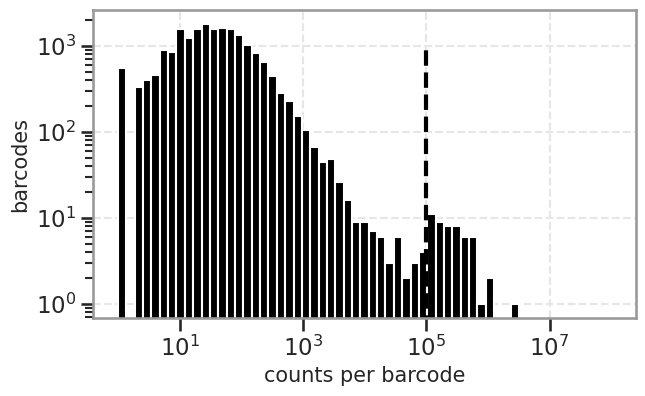

barcodes above the upper cutoff (excluded as pre-existing mutants): 52 of 119724 (0.043%)
Done in 10.0s.


In [7]:
counts_tf = load_npz(DATA / "D709_D506_errorCorrectedBcds.npz")
counts_f = np.array([counts_tf[i, 0] for i in bcds])
fig = plt.figure(); fig.set_size_inches(7, 4)
plt.hist(counts_f, bins=np.logspace(0, 8, 60), color="k")
plt.xscale("log"); plt.yscale("log")
plt.plot([UPPERCUTOFF, UPPERCUTOFF], [0, 1000], '--k', linewidth=3)
plt.xlabel("counts per barcode"); plt.ylabel("barcodes")
plt.savefig(OUT / "figS01f_umisPerBarcode_tf.svg", dpi=300); plt.show()

n_excluded = int(np.sum(counts_f >= UPPERCUTOFF))
print(f"barcodes above the upper cutoff (excluded as pre-existing mutants): "
      f"{n_excluded} of {len(bcds)} ({100*n_excluded/len(bcds):.3f}%)")
print(f"Done in {time.time()-t_start:.1f}s.")